# 03-1　狹義相對論：拆掉牛頓的絕對時間

**前置**：[00-3 觀看前須知](../00_basics/03_before_relativity.ipynb)

**這一課打開 $1/c$**：牛頓力學隱含 $c = \infty$（訊號可以瞬間傳到），現在讓光速變成有限的 $c$，而且對所有人都一樣。

結果是牛頓的**絕對時間**被拆掉了，也就是 02 單元薛丁格方程式裡、量子力學保留下來的那個 $t$。

1. 用光鐘和畢氏定理**推導**時間變慢（用 sympy 讓電腦做代數）
2. **真實數據**：從山頂跑到海平面的緲子，牛頓說幾乎全死光，實際上活下來七成
3. 勞倫茲轉換與**同時的相對性**：你的「同時」不是我的「同時」
4. **雙生子悖論**：太空旅行回來，誰比較年輕？
5. 速度加法：為什麼怎麼加都超不過光速
6. **真實數據**：GPS 衛星的時鐘每天慢多少
7. $E = mc^2$，以及 $c \to \infty$ 時回到牛頓

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import sympy as sp

plt.rcParams["font.family"] = ["Microsoft JhengHei", "sans-serif"]  # 中文標籤
plt.rcParams["axes.unicode_minus"] = False
plt.rcParams["figure.dpi"] = 100

c = 299_792_458.0   # 光速 (m/s)


def gamma(beta):
    return 1 / np.sqrt(1 - np.asarray(beta) ** 2)

## 實驗 1：從光鐘推導時間變慢

00-3 第 4 章的光鐘：鏡子間距 $h$。

- **火車上**（光鐘靜止）：光上去一趟花 $\Delta\tau = h / c$。$\tau$ 是**光鐘自己**量到的時間，叫**固有時**。
- **月台上**：光走斜線，花了 $\Delta t$。三角形的三邊是 $c\Delta t$（斜邊）、$v\Delta t$（底）、$h = c\Delta\tau$（高）。

用畢氏定理列出方程式，讓 sympy 解出 $\Delta t$：

In [2]:
c_s, v_s, dt, dtau = sp.symbols("c v Delta_t Delta_tau", positive=True)

pythagoras = sp.Eq((c_s * dt) ** 2, (v_s * dt) ** 2 + (c_s * dtau) ** 2)
display(pythagoras)

# 先解 Δt²（避免 sympy 不知道 v < c 而搞錯正負號）
dt2 = sp.solve(pythagoras.subs(dt, sp.sqrt(sp.Symbol("X", positive=True))), sp.Symbol("X", positive=True))[0]
display(sp.Eq(dt**2, dt2))

# 驗證：它就等於 Δτ² / (1 − v²/c²)
claimed = dtau / sp.sqrt(1 - v_s**2 / c_s**2)
print("Δt² − (Δτ/√(1 − v²/c²))² 化簡後 =", sp.simplify(dt2 - claimed**2))
display(sp.Eq(dt, claimed))

Eq(Delta_t**2*c**2, Delta_t**2*v**2 + Delta_tau**2*c**2)

Eq(Delta_t**2, Delta_tau**2*c**2/(c**2 - v**2))

Δt² − (Δτ/√(1 − v²/c²))² 化簡後 = 0


Eq(Delta_t, Delta_tau/sqrt(1 - v**2/c**2))

得到

$$\Delta t = \frac{\Delta\tau}{\sqrt{1 - v^2/c^2}} = \gamma\,\Delta\tau$$

**月台上的人量到的時間，比光鐘自己量到的長 $\gamma$ 倍。** 也就是說，從月台上看，火車上的鐘**走得比較慢**。

這不是光鐘的特殊性質。依照相對性原理，火車上**所有**的物理過程（心跳、化學反應、原子振動、粒子衰變）都必須一起變慢，
否則火車上的人只要比較光鐘和手錶，就能知道自己在動，違反相對性原理。

**時間本身變慢了。**

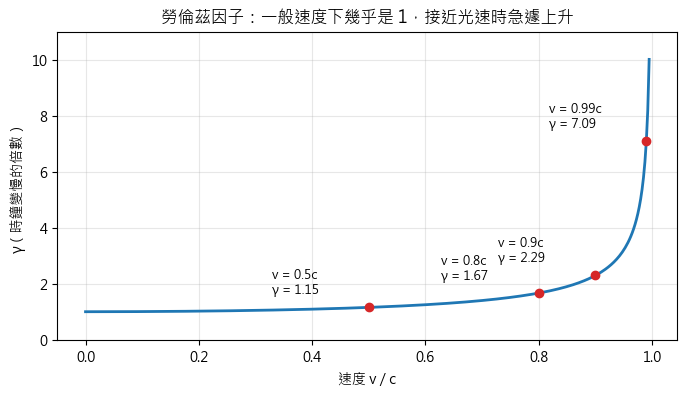

In [3]:
betas = np.linspace(0, 0.995, 400)
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(betas, gamma(betas), lw=2)
for b in [0.5, 0.8, 0.9, 0.99]:
    ax.plot(b, gamma(b), "o", color="C3")
    ax.annotate(f"v = {b}c\nγ = {gamma(b):.2f}", (b, gamma(b)), xytext=(-70, 10), textcoords="offset points", fontsize=9)
ax.set_xlabel("速度 v / c")
ax.set_ylabel("γ（時鐘變慢的倍數）")
ax.set_title("勞倫茲因子：一般速度下幾乎是 1，接近光速時急遽上升")
ax.set_ylim(0, 11)
ax.grid(alpha=0.3)
plt.show()

## 實驗 2：真實數據，山頂和海平面的緲子

**緲子**是一種基本粒子，像是比較重的電子。宇宙射線撞上高空大氣時會產生大量緲子，以接近光速往地面飛。
緲子不穩定，**平均壽命 2.2 μs**（在它自己的參考系裡），之後就衰變成別的粒子。

**1963 年 Frisch 和 Smith 的實驗**：在美國華盛頓山山頂（海拔 1910 m）和海平面各放一台偵測器，
只計算速度約 $0.995c$ 的緲子：

- 山頂：每小時約 **563** 個
- 海平面：每小時約 **408** 個

從山頂飛到海平面約 1907 m，在地面上看要花約 6.4 μs，差不多是**三倍的平均壽命**。牛頓和相對論的預測差了一大截：

In [4]:
tau_mu = 2.197e-6         # 緲子平均壽命（自身參考系）(s)
height = 1907.0           # 山頂到海平面 (m)
v_mu = 0.995 * c
N_top, N_sea_measured = 563, 408

t_lab = height / v_mu
survive_newton = np.exp(-t_lab / tau_mu)

# 緲子穿過大氣時會減速，實驗量到的平均時間變慢倍數約 8.8
g_eff = 8.8
survive_rel = np.exp(-t_lab / g_eff / tau_mu)

print(f"地面上看，飛行時間 = {t_lab * 1e6:.2f} μs = {t_lab / tau_mu:.1f} 倍壽命")
print(f"\n{'':<24}{'存活比例':>10}{'海平面每小時':>14}")
print(f"{'牛頓（時鐘不變慢）':<22}{survive_newton:>10.1%}{N_top * survive_newton:>14.0f}")
print(f"{'相對論（緲子的鐘慢 8.8 倍）':<20}{survive_rel:>10.1%}{N_top * survive_rel:>14.0f}")
print(f"{'實際測量':<24}{N_sea_measured / N_top:>10.1%}{N_sea_measured:>14}")
print(f"\n緲子自己的時鐘只過了 {t_lab / g_eff * 1e6:.2f} μs")

地面上看，飛行時間 = 6.39 μs = 2.9 倍壽命

                              存活比例        海平面每小時
牛頓（時鐘不變慢）                   5.4%            31
相對論（緲子的鐘慢 8.8 倍）         71.8%           404
實際測量                         72.5%           408

緲子自己的時鐘只過了 0.73 μs


**觀察**：

- 牛頓預測海平面每小時只剩約 30 個，實際上有 408 個，**差了十幾倍**。
- 相對論預測約 400 個，和實驗吻合。
- 從緲子自己的角度看：它的時鐘只過了 0.7 μs，還不到一個壽命。
  （它看到的是另一回事：**整座山變矮了** 8.8 倍，這叫**長度收縮**。兩種說法得到同樣的答案。）

宇宙射線緲子每分鐘都有很多穿過你的身體。**它們能到達地面，本身就是時間變慢的證據。**

## 實驗 3：勞倫茲轉換與同時的相對性

如果在月台的參考系裡，一件事發生在 $(x, t)$，那在以速度 $v$ 前進的火車參考系裡，它發生在哪裡、什麼時候？

**牛頓（伽利略轉換）**：$x' = x - vt$，$t' = t$。時間對所有人都一樣。

**相對論（勞倫茲轉換）**：

$$x' = \gamma\,(x - vt),\qquad t' = \gamma\left(t - \frac{vx}{c^2}\right)$$

$t'$ 的式子裡出現了 $x$：**時間和位置混在一起了**。最驚人的後果是**同時的相對性**：

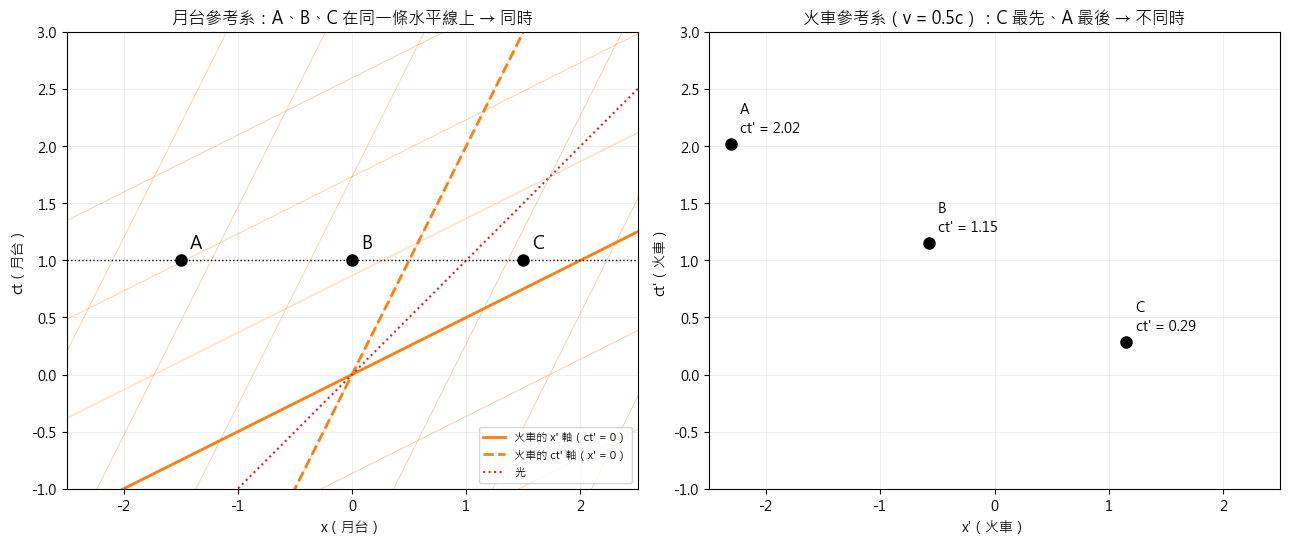

In [5]:
def lorentz(x, ct, beta):
    g = gamma(beta)
    return g * (x - beta * ct), g * (ct - beta * x)

beta = 0.5
events = {"A": (-1.5, 1.0), "B": (0.0, 1.0), "C": (1.5, 1.0)}   # 在月台上「同時」發生（ct = 1）

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))

ax = axes[0]
s = np.linspace(-3, 3, 2)
for k in range(-3, 4):   # 火車參考系的格線：ct' = 常數、x' = 常數
    ax.plot(s, beta * s + k / gamma(beta) , color="C1", lw=0.5, alpha=0.5)
    ax.plot(beta * s + k / gamma(beta), s, color="C1", lw=0.5, alpha=0.5)
ax.plot(s, beta * s, "C1", lw=2, label="火車的 x' 軸（ct' = 0）")
ax.plot(beta * s, s, "C1--", lw=2, label="火車的 ct' 軸（x' = 0）")
ax.plot(s, s, "C3:", lw=1.5, label="光")
ax.axhline(1, color="k", lw=1, ls=":")
for name, (x, ct) in events.items():
    ax.plot(x, ct, "ko", ms=8)
    ax.text(x + 0.08, ct + 0.1, name, fontsize=13)
ax.set_xlim(-2.5, 2.5)
ax.set_ylim(-1, 3)
ax.set_aspect("equal")
ax.set_xlabel("x（月台）")
ax.set_ylabel("ct（月台）")
ax.set_title("月台參考系：A、B、C 在同一條水平線上 → 同時")
ax.legend(loc="lower right", fontsize=8)
ax.grid(alpha=0.2)

ax = axes[1]
for name, (x, ct) in events.items():
    xp, ctp = lorentz(x, ct, beta)
    ax.plot(xp, ctp, "ko", ms=8)
    ax.text(xp + 0.08, ctp + 0.1, f"{name}\nct' = {ctp:.2f}", fontsize=10)
ax.set_xlim(-2.5, 2.5)
ax.set_ylim(-1, 3)
ax.set_aspect("equal")
ax.set_xlabel("x'（火車）")
ax.set_ylabel("ct'（火車）")
ax.set_title(f"火車參考系（v = {beta}c）：C 最先、A 最後 → 不同時")
ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

**觀察**：

- 月台上的人看到 A、B、C **同時**發生。
- 火車上的人看到 **C 先發生，然後 B，最後 A**。
- 兩個人都是對的。「同時」**不是絕對的**，取決於你在哪個參考系。

左圖的橘色格線是火車參考系的座標：時間軸和空間軸都**斜了**，像剪刀一樣往光線（45°）合攏。
火車的「同一時刻」是沿著斜的 $x'$ 軸，而不是水平線。

**這就是牛頓絕對時間的終結**：宇宙裡沒有一個大家共用的「現在」。
所以 02 單元薛丁格方程式裡那個 $t$，到底是**誰的**時間？在狹義相對論裡，量子力學還能透過「量子場論」挑一個參考系來用，
但到了 04 單元的廣義相對論，連「挑一個參考系」都變得沒有意義。

## 實驗 4：雙生子悖論

一對雙胞胎，姊姊留在地球，妹妹搭太空船以 $0.8c$ 飛到 4 光年外的星球，再以 $0.8c$ 飛回來。

**悖論**：從姊姊看，妹妹在動，所以妹妹比較年輕；可是從妹妹看，是地球在動，那姊姊不就比較年輕嗎？

**答案**：兩人的處境**不對稱**。妹妹在折返點**轉向**（換了參考系），姊姊一直待在同一個參考系。
要比較誰經歷的時間比較多，就沿著各自的世界線把**固有時**加起來：

$$\tau = \int \sqrt{1 - v(t)^2/c^2}\;dt$$

姊姊（地球）：經過 10.0 年
妹妹（太空船）：經過 6.00 年（公式：6.00 年）
妹妹回來時比姊姊年輕 4.0 歲


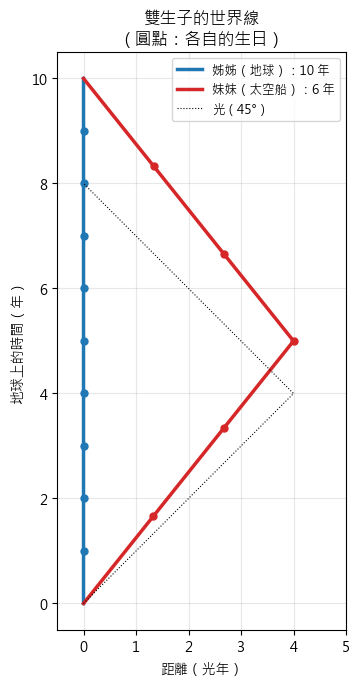

In [6]:
D, beta_trip = 4.0, 0.8          # 光年、速度
T_earth = 2 * D / beta_trip      # 地球上經過的時間（年）

t = np.linspace(0, T_earth, 2001)
x_sister = np.where(t < T_earth / 2, beta_trip * t, 2 * D - beta_trip * t)
v_sister = np.gradient(x_sister, t)
tau_sister = np.concatenate([[0], np.cumsum(np.sqrt(1 - v_sister[1:] ** 2) * np.diff(t))])

print(f"姊姊（地球）：經過 {T_earth:.1f} 年")
print(f"妹妹（太空船）：經過 {tau_sister[-1]:.2f} 年（公式：{T_earth / gamma(beta_trip):.2f} 年）")
print(f"妹妹回來時比姊姊年輕 {T_earth - tau_sister[-1]:.1f} 歲")

fig, ax = plt.subplots(figsize=(6, 7.5))
ax.plot(np.zeros_like(t), t, "C0", lw=2.5, label=f"姊姊（地球）：{T_earth:.0f} 年")
ax.plot(x_sister, t, "C3", lw=2.5, label=f"妹妹（太空船）：{tau_sister[-1]:.0f} 年")
for yr in range(1, int(T_earth)):
    ax.plot(0, yr, "o", color="C0", ms=5)
for yr in range(1, int(tau_sister[-1])):
    i = np.argmin(np.abs(tau_sister - yr))
    ax.plot(x_sister[i], t[i], "o", color="C3", ms=5)
ax.plot([0, D, 0], [0, D, 2 * D], "k:", lw=0.8, label="光（45°）")
ax.set_xlabel("距離（光年）")
ax.set_ylabel("地球上的時間（年）")
ax.set_xlim(-0.5, 5)
ax.set_aspect("equal")
ax.set_title("雙生子的世界線\n（圓點：各自的生日）")
ax.legend(loc="upper right", fontsize=9)
ax.grid(alpha=0.3)
plt.show()

**觀察**：

- 姊姊過了 10 年、10 次生日；妹妹只過了 6 年、6 次生日。妹妹的生日點在世界線上**比較稀疏**。
- 在時空圖上，妹妹的路徑**看起來比較長**，但經歷的時間比較**短**。

這一點很重要：在相對論的時空裡，**兩點之間的直線，是固有時最「長」的路徑**。
任何繞路（加速、轉向）都會讓你的時鐘走得比較少，這和平常的幾何剛好相反（平面上的直線是**最短**的路徑）。

到了 04 單元，這會變成廣義相對論的核心：**自由落下的物體，走的是讓固有時最大的路徑**（測地線）。行星繞太陽，就是在彎曲的時空裡走「最直的路」。

## 實驗 5：速度加法，為什麼超不過光速

00-3 第 1 章的伽利略加法 $u = u' + v$。相對論的版本是：

$$u = \frac{u' + v}{1 + u'v/c^2}$$

0.5 c + 0.5 c：伽利略 = 1 c，相對論 = 0.8 c
0.8 c + 0.8 c：伽利略 = 1.6 c，相對論 = 0.97561 c
0.99 c + 0.99 c：伽利略 = 1.98 c，相對論 = 0.999949 c
1.0 c + 0.8 c：伽利略 = 1.8 c，相對論 = 1 c
1e-06 c + 1e-06 c：伽利略 = 2e-06 c，相對論 = 2e-06 c


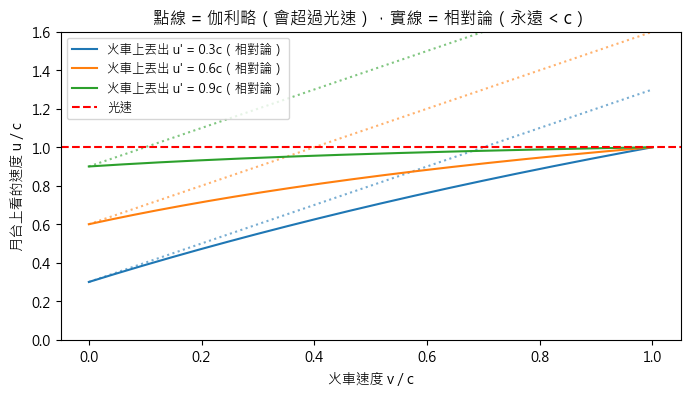

In [7]:
def add_velocity(u_prime, v):   # 單位：c
    return (u_prime + v) / (1 + u_prime * v)

for a, b in [(0.5, 0.5), (0.8, 0.8), (0.99, 0.99), (1.0, 0.8), (1e-6, 1e-6)]:
    print(f"{a} c + {b} c：伽利略 = {a + b:.6g} c，相對論 = {add_velocity(a, b):.6g} c")

vs = np.linspace(0, 1, 200)
fig, ax = plt.subplots(figsize=(8, 4))
for up in [0.3, 0.6, 0.9]:
    ax.plot(vs, add_velocity(up, vs), label=f"火車上丟出 u' = {up}c（相對論）")
    ax.plot(vs, up + vs, ":", color=ax.lines[-1].get_color(), alpha=0.6)
ax.axhline(1, color="r", ls="--", label="光速")
ax.set_xlabel("火車速度 v / c")
ax.set_ylabel("月台上看的速度 u / c")
ax.set_ylim(0, 1.6)
ax.set_title("點線 = 伽利略（會超過光速），實線 = 相對論（永遠 < c）")
ax.legend(loc="upper left", fontsize=9)
plt.show()

**觀察**：0.8c 加 0.8c 是 0.976c，不是 1.6c。把光（$u' = c$）加上任何速度，結果**還是 c**，這正是光速不變的要求。
速度很小時（最後一行），相對論和伽利略完全一樣。

## 實驗 6：GPS 衛星的時鐘（狹義相對論的部分）

GPS 衛星以約 3.87 km/s 繞地球（00-3 第 7 章）。從地面看，它的原子鐘每天會慢多少？

In [8]:
GM_earth = 3.986004418e14
r_gps = 26_561.75e3                       # GPS 軌道半徑 (m)
v_gps = np.sqrt(GM_earth / r_gps)
day = 86_400.0

# 地面的時鐘也跟著地球自轉在動（赤道約 465 m/s），這裡先只看衛星
slow_fraction = np.expm1(-0.5 * np.log1p(-(v_gps / c) ** 2))   # γ − 1，避免浮點相減誤差
print(f"衛星速度 v = {v_gps:.0f} m/s，v/c = {v_gps / c:.3e}")
print(f"時鐘變慢的比例 γ − 1 = {slow_fraction:.3e}")
print(f"每天慢 {slow_fraction * day * 1e6:.2f} μs")
print(f"換算成定位誤差：每天 {slow_fraction * day * c / 1000:.1f} km")

衛星速度 v = 3874 m/s，v/c = 1.292e-05
時鐘變慢的比例 γ − 1 = 8.349e-11
每天慢 7.21 μs
換算成定位誤差：每天 2.2 km


**每天慢約 7.2 μs**，換成距離每天累積約 2 公里的誤差。

但這只是一半。衛星在高空，**重力比較弱**，廣義相對論說那裡的時鐘會走得比較**快**，而且效應更大。
兩者合起來，才是工程師真正寫進 GPS 系統的修正值。04 單元會把另一半算出來。

**歷史上的直接驗證**：1971 年，Hafele 和 Keating 帶著四台銫原子鐘搭民航機繞地球一圈，回來和地面的鐘比較。
往東飛的鐘慢了約 59 ns，往西飛的鐘快了約 273 ns，和相對論（狹義加廣義）的預測吻合。

## 實驗 7：$E = mc^2$，以及 $c \to \infty$ 回到牛頓

相對論裡，一個質量 $m$、速度 $v$ 的物體，總能量是

$$E = \gamma\,mc^2$$

靜止時（$\gamma = 1$）還剩 $E = mc^2$：**質量本身就是能量**。動能就是總能量減掉靜止能量 $(\gamma - 1)mc^2$。

用 sympy 把它在 $v$ 很小時展開：

In [9]:
m_s = sp.symbols("m", positive=True)
gamma_s = 1 / sp.sqrt(1 - v_s**2 / c_s**2)
kinetic = (gamma_s - 1) * m_s * c_s**2

display(sp.Eq(sp.Symbol("E_k"), sp.series(kinetic, v_s, 0, 6).removeO()))

Eq(E_k, m*v**2/2 + 3*m*v**4/(8*c**2))

第一項是 $\frac12 mv^2$，**就是高中的動能公式**，後面的項都帶著 $1/c^2$。
光速無限大時，後面的項全部消失，剩下牛頓的公式。

再看勞倫茲轉換在 $c \to \infty$ 時變成什麼：

In [10]:
x_s, t_s = sp.symbols("x t", real=True)
x_prime = gamma_s * (x_s - v_s * t_s)
t_prime = gamma_s * (t_s - v_s * x_s / c_s**2)

print("c → ∞ 時：")
display(sp.Eq(sp.Symbol("x'"), sp.limit(x_prime, c_s, sp.oo)))
display(sp.Eq(sp.Symbol("t'"), sp.limit(t_prime, c_s, sp.oo)))

c → ∞ 時：


Eq(x', -t*v + x)

Eq(t', t)

**$c \to \infty$ 時，勞倫茲轉換變回伽利略轉換**：$x' = x - vt$，$t' = t$，時間又變回絕對的了。

這和 02 的 $\hbar \to 0$ 是同一個模式：**舊理論是新理論在某個常數取極限時的特例。**

**$E = mc^2$ 有多大？** $c^2$ 約是 $9\times10^{16}$，所以 1 公克的質量完全轉成能量，約有 $9\times10^{13}$ 焦耳，相當於 2 萬公噸 TNT。
太陽每秒把約 **420 萬公噸**的質量轉成光和熱（核融合，02-2 提到的穿隧讓它發生）。

In [11]:
L_sun = 3.828e26                      # 太陽光度 (W)
dm_dt = L_sun / c**2
print(f"太陽每秒損失的質量 = L/c² = {dm_dt:.2e} kg = {dm_dt / 1000 / 1e6:.2f} 百萬公噸")

太陽每秒損失的質量 = L/c² = 4.26e+09 kg = 4.26 百萬公噸


## 總結

| 實驗 | 結果 | 牛頓的哪個假設被拆掉 |
|---|---|---|
| 光鐘 | 移動的時鐘慢 $\gamma$ 倍 | 時間對所有人一樣快 |
| 緲子 | 牛頓預測 30 個，實際 408 個 | |
| 勞倫茲轉換 | 同時是相對的 | **全宇宙共用的「現在」** |
| 雙生子 | 走直線的人最老 | |
| 速度加法 | 永遠超不過 $c$ | 速度直接相加 |
| GPS | 衛星鐘每天慢 7.2 μs | |
| $E = mc^2$ | 質量是能量 | 質量和能量是兩回事 |
| $c \to \infty$ | 全部回到牛頓 | |

**和大問題的關係**：

- 狹義相對論拆掉了**絕對時間**，換成一個四維的**時空**。但這個時空還是**平坦、固定的舞台**，不會被物質影響。
- 量子力學和狹義相對論**可以**合併，結果就是**量子場論**，粒子物理的標準模型。它非常成功，但依賴一個固定的平坦時空當背景。
- 下一步（04）：**讓舞台本身也動起來**。物質讓時空彎曲，時空告訴物質怎麼運動。到那時，量子場論需要的「固定背景」就不存在了，衝突也從這裡開始。

## 練習

1. 實驗 2：如果緲子的速度是 $0.9c$，海平面每小時會剩多少個？（記得 $\gamma$ 要重算。）
2. 實驗 4：如果妹妹以 $0.99c$ 去 4 光年外再回來，她會比姊姊年輕幾歲？
3. 實驗 6：國際太空站（7.66 km/s）上的太空人待了 6 個月，因為狹義相對論，他比地面的人少老了多少？